In [ ]:
# FASE 1: PREPROCESAMIENTO (nulos, outliers y transformaciones)

# 1. Carga y limpieza de nombres de columnas
import pandas as pd
import numpy as np
import unicodedata
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

RUTA = r"Datos_Complementarios_CLV.xlsx"    
HOJA = "Histórico_Ventas"               

df = pd.read_excel(RUTA, sheet_name=HOJA)
df.columns = df.columns.str.strip()     
df = df.rename(columns={"marc": "marca"})
print("Filas y columnas:", df.shape)

# 2. Tipos de dato
df["fecha_documento"] = pd.to_datetime(df["fecha_documento"], format="%d.%m.%Y", errors="coerce")
print("Fechas no convertidas:", df["fecha_documento"].isna().sum())

# articulo_id y cp son identificadores, se tratan como texto.
df["articulo_id"] = df["articulo_id"].astype(str)
df["cp"] = df["cp"].astype("Int64").astype("string")
# Decisión sobre nulos de cp (2.27%, concentrados en Puebla): no se imputan.
# cp no entra a ningún modelo; la ubicación se representa con 'estado'.
print("Nulos de cp:", df["cp"].isna().sum())

#3. Normalización de texto
def norm(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return " ".join(s.upper().split())

cols_texto = ["folio_abreviado", "folio", "nombre_articulo", "marca",
              "nombre_cliente", "estado", "ciudad", "vendedor"]
for c in cols_texto:
    df[c] = df[c].map(norm)

# Verificación antes de unificar
print("\nCiudades dentro de estado == 'MEXICO':")
print(df.loc[df["estado"] == "MEXICO", "ciudad"].value_counts().head(10))

df["estado"] = df["estado"].replace({"MEXICO": "ESTADO DE MEXICO",
                                     "SIN ESTADO": "SIN DATO"})
print("\nEstados distintos tras limpiar:", df["estado"].nunique())
print(sorted(df["estado"].unique()))
print("Categorías -> marca:", df["marca"].nunique(), "| vendedor:", df["vendedor"].nunique(),
      "| cliente:", df["nombre_cliente"].nunique())

#4. Duplicados (se marcan, NO se eliminan: se hace prueba de sensibilidad)
df["dup_exacta"] = df.duplicated(keep="first")
d = df[df["dup_exacta"]]
print("Duplicadas exactas (tras normalizar):", len(d))
print("Folios afectados:", d["folio"].nunique(),
      "| máx. duplicadas en un folio:", d.groupby("folio").size().max())
print("% con total_neto = 0:", round((d["total_neto"] == 0).mean() * 100, 1))
print("\nPor serie de folio:")
print(d.groupby("folio_abreviado").size().sort_values(ascending=False))

#5. Ceros: partidas sin costo vs. ventas reales
df["sin_costo"] = (df["total_neto"] == 0).astype(int)
print(df["sin_costo"].value_counts())
print("Proporción sin costo:", round(df["sin_costo"].mean() * 100, 2), "%")

# Base de ventas reales (para regresiones lineales)
df_ventas = df[df["sin_costo"] == 0].copy()
print("Partidas con costo:", len(df_ventas))

#6. Agrupación de categorías raras (umbrales editables)
def agrupar(serie, minimo, otro="OTROS"):
    vc = serie.value_counts()
    keep = vc[vc >= minimo].index
    return serie.where(serie.isin(keep), otro)

df["marca_g"] = agrupar(df["marca"], 150, "OTRAS")
df["estado_g"] = agrupar(df["estado"], 700, "OTROS")
df["vendedor_g"] = agrupar(df["vendedor"], 800, "OTROS")
df["folio_g"] = agrupar(df["folio_abreviado"], 100, "OTRA_SERIE")

for c in ["marca_g", "estado_g", "vendedor_g", "folio_g"]:
    print(f"\n{c}: {df[c].nunique()} categorías")
    print(df[c].value_counts())

# Se propagan las agrupaciones a la base de ventas
df_ventas = df[df["sin_costo"] == 0].copy()

#7. Outliers y transformación logarítmica (solo ventas reales)
df_ventas["log_precio"] = np.log(df_ventas["precio_unitario"])
df_ventas["log_unidades"] = np.log(df_ventas["total_unidades"])
df_ventas["log_total"] = np.log(df_ventas["total_neto"])

def iqr_out(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

filas = []
for orig, lg in [("precio_unitario", "log_precio"),
                 ("total_unidades", "log_unidades"),
                 ("total_neto", "log_total")]:
    filas.append({"variable": orig,
                  "sesgo_original": round(df_ventas[orig].skew(), 2),
                  "sesgo_log": round(df_ventas[lg].skew(), 2),
                  "outliers_IQR_original": iqr_out(df_ventas[orig]),
                  "outliers_IQR_log": iqr_out(df_ventas[lg])})
print(pd.DataFrame(filas))

# Partidas donde total_neto no es precio x unidades (se conservan, solo se cuantifican)
ratio = df_ventas["total_neto"] / (df_ventas["precio_unitario"] * df_ventas["total_unidades"])
print("\nPartidas con total != precio x unidades (±1%):", int(((ratio - 1).abs() > 0.01).sum()),
      "| ratio < 1:", int((ratio < 0.99).sum()), "| ratio > 1:", int((ratio > 1.01).sum()))

#8. Tabla por cliente (solo ventas reales)
USAR_SIN_DUPLICADOS = False   # cambia a True para la prueba de sensibilidad
base = df_ventas[~df_ventas["dup_exacta"]] if USAR_SIN_DUPLICADOS else df_ventas

g = base.groupby("nombre_cliente")
cliente = g.agg(
    total_comprado=("total_neto", "sum"),
    n_folios=("folio", "nunique"),
    n_lineas=("folio", "size"),
    unidades=("total_unidades", "sum"),
    n_marcas=("marca", "nunique"),
    n_articulos=("articulo_id", "nunique"),
    primera=("fecha_documento", "min"),
    ultima=("fecha_documento", "max"),
)
cliente["dias_activo"] = (cliente["ultima"] - cliente["primera"]).dt.days
cliente["ticket_prom_folio"] = cliente["total_comprado"] / cliente["n_folios"]

moda = lambda x: x.mode().iloc[0]
cliente["estado_principal"] = g["estado_g"].agg(moda)
cliente["vendedor_principal"] = g["vendedor_g"].agg(moda)
cliente["marca_principal"] = (base.groupby(["nombre_cliente", "marca_g"])["total_neto"].sum()
                                  .reset_index()
                                  .sort_values("total_neto", ascending=False)
                                  .drop_duplicates("nombre_cliente")
                                  .set_index("nombre_cliente")["marca_g"])

cliente["log_total_comprado"] = np.log(cliente["total_comprado"])
cliente["log_unidades"] = np.log(cliente["unidades"])
cliente["log_lineas"] = np.log(cliente["n_lineas"])

print("Clientes en la tabla:", len(cliente),
      "| clientes excluidos (solo partidas sin costo):",
      df["nombre_cliente"].nunique() - len(cliente))

#9. Revisión de la tabla por cliente
print(cliente.describe().round(2))
print("\nNulos:\n", cliente.isna().sum()[cliente.isna().sum() > 0])
print("\nClientes con 1 solo folio:", round((cliente["n_folios"] == 1).mean() * 100, 1), "%")

num = ["total_comprado", "ticket_prom_folio", "n_folios", "n_lineas",
       "unidades", "n_marcas", "n_articulos", "dias_activo"]
sp = cliente[num].corr(method="spearman")
print("\nSpearman:\n", sp.round(2))

print("\nPares con |Spearman| > 0.9 (posible colinealidad o relación algebraica):")
for i, a in enumerate(num):
    for b in num[i + 1:]:
        if abs(sp.loc[a, b]) > 0.9:
            print(f"  {a} ~ {b}: {sp.loc[a, b]:.2f}")

#10. ¿Qué tan relacionada está la serie de folio con el estado?
from scipy.stats import chi2_contingency
tab = pd.crosstab(df["folio_g"], df["estado_g"])
chi2, p, dof, _ = chi2_contingency(tab)
n = tab.values.sum()
v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
print(f"chi2 = {chi2:.1f} | p = {p:.3g} | V de Cramér = {v:.3f}")
print("(V cercana a 0 = sin relación; cercana a 1 = relación fuerte)")

#11. Guardar tablas limpias (solo en tu computadora)
df.to_pickle("df_partidas_limpio.pkl")
cliente.to_pickle("df_cliente.pkl")
print("Guardado: df_partidas_limpio.pkl y df_cliente.pkl")


Filas y columnas: (21632, 14)
Fechas no convertidas: 0
Nulos de cp: 492

Ciudades dentro de estado == 'MEXICO':
ciudad
TOLU                   3
SAN ANTONIO LA ISLA    1
Name: count, dtype: int64

Estados distintos tras limpiar: 33
['AGUASCALIENTES', 'BAJA CALIFORNIA', 'BAJA CALIFORNIA SUR', 'CAMPECHE', 'CHIAPAS', 'CHIHUAHUA', 'CIUDAD DE MEXICO', 'COAHUILA', 'COLIMA', 'DURANGO', 'ESTADO DE MEXICO', 'GUANAJUATO', 'GUERRERO', 'HIDALGO', 'JALISCO', 'MICHOACAN', 'MORELOS', 'NAYARIT', 'NUEVO LEON', 'OAXACA', 'PUEBLA', 'QUERETARO', 'QUINTANA ROO', 'SAN LUIS POTOSI', 'SIN DATO', 'SINALOA', 'SONORA', 'TABASCO', 'TAMAULIPAS', 'TLAXCALA', 'VERACRUZ', 'YUCATAN', 'ZACATECAS']
Categorías -> marca: 25 | vendedor: 77 | cliente: 1684
Duplicadas exactas (tras normalizar): 185
Folios afectados: 66 | máx. duplicadas en un folio: 40
% con total_neto = 0: 3.8

Por serie de folio:
folio_abreviado
A00    103
CP0     24
XP0     19
B00     18
XDF     14
XS0      4
S00      3
dtype: int64
sin_costo
0    20020
1 

Clientes: 1682 | outliers IQR en log_total_comprado: 1 | sesgo de log_total_comprado: 0.32


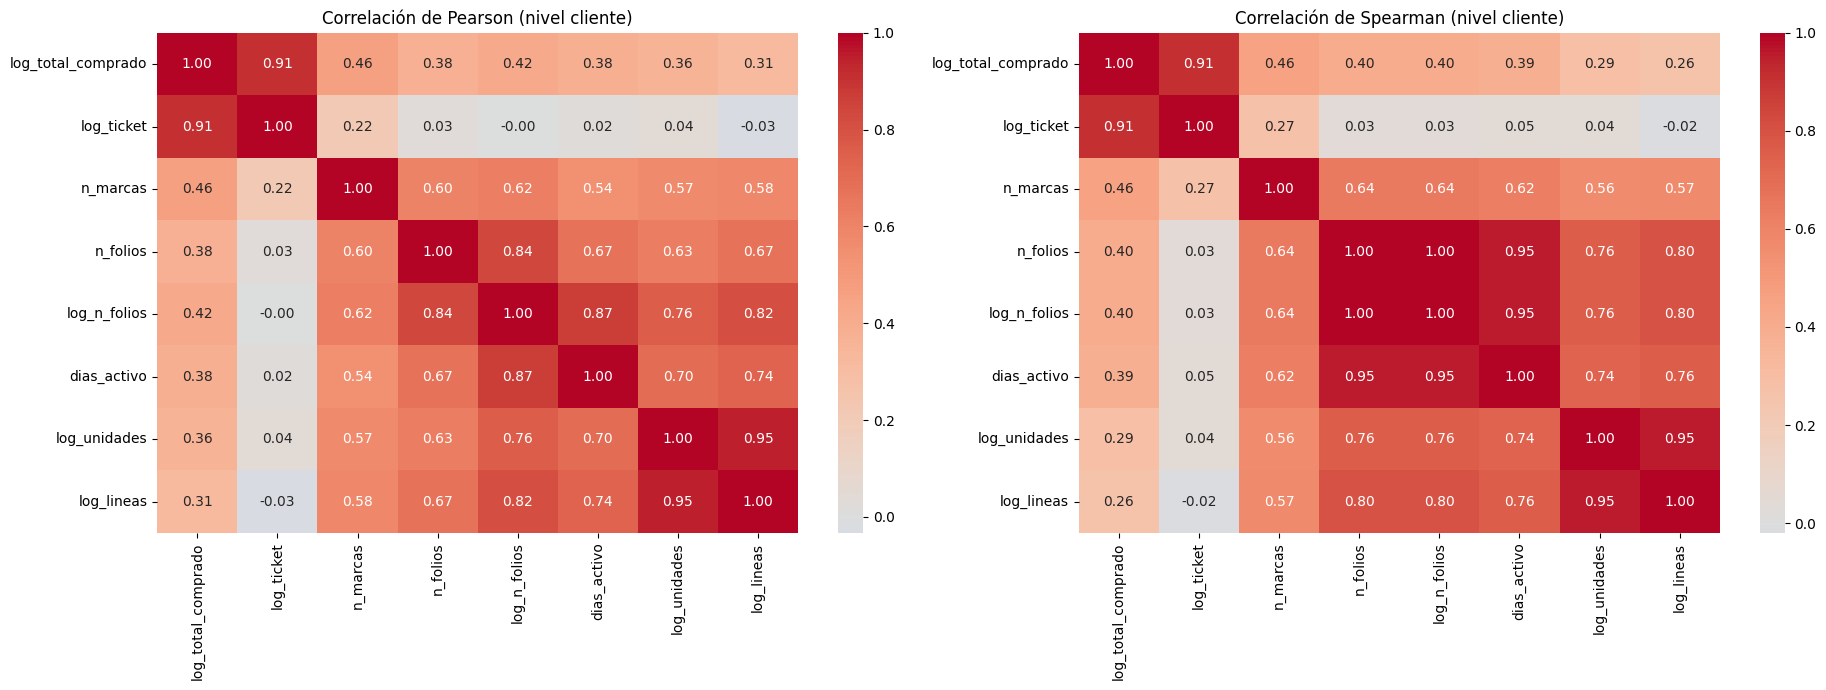

              pearson  spearman  abs_pearson
n_marcas        0.462     0.459        0.462
log_n_folios    0.419     0.402        0.419
dias_activo     0.385     0.389        0.385
n_folios        0.377     0.402        0.377
log_unidades    0.361     0.291        0.361
log_lineas      0.315     0.260        0.315

Relación algebraica (solo referencia): r(log_ticket, Y) = 0.907
Variable elegida para el modelo simple: n_marcas

Ecuación: log_total_comprado = 7.8353 + 0.8614 * n_marcas
r = 0.4625 | R2 = 0.2139 | p-valor = 6.77e-90 | n = 1682


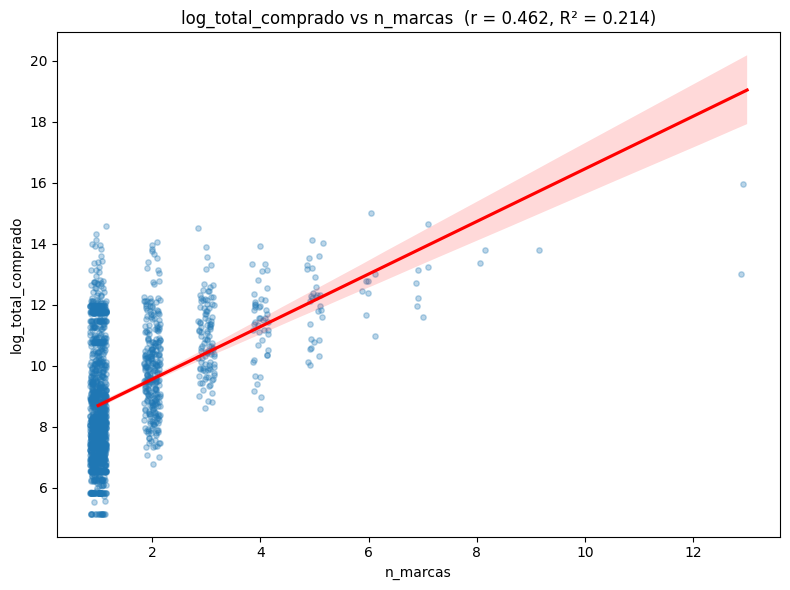


Sensibilidad sin outliers (n = 1681): pendiente 0.8801 | R2 0.2101  (con todos: pendiente 0.8614 | R2 0.2139)
estado_principal: 8 categorías | referencia = OTROS
marca_principal: 11 categorías | referencia = VITA
vendedor_principal: 10 categorías | referencia = OTROS
Predictoras candidatas: 29
Se quita por p = 0.968: estado_principal_JALISCO
Se quita por p = 0.953: estado_principal_GUANAJUATO
Se quita por p = 0.845: estado_principal_QUERETARO
Se quita por p = 0.796: estado_principal_BAJA CALIFORNIA
Se quita por p = 0.637: vendedor_principal_ESMERALDA
Se quita por p = 0.639: estado_principal_PUEBLA
Se quita por p = 0.339: vendedor_principal_JAIME
Se quita por p = 0.342: vendedor_principal_ALEJANDRA
Se quita por p = 0.190: vendedor_principal_RENE
Se quita por p = 0.152: marca_principal_HUGE
Se quita por p = 0.117: vendedor_principal_JAVIERCAD
Se quita por p = 0.089: marca_principal_IPD
Se quita por p = 0.088: vendedor_principal_DIEGO
Se quita por p = 0.499: estado_principal_ESTADO DE ME

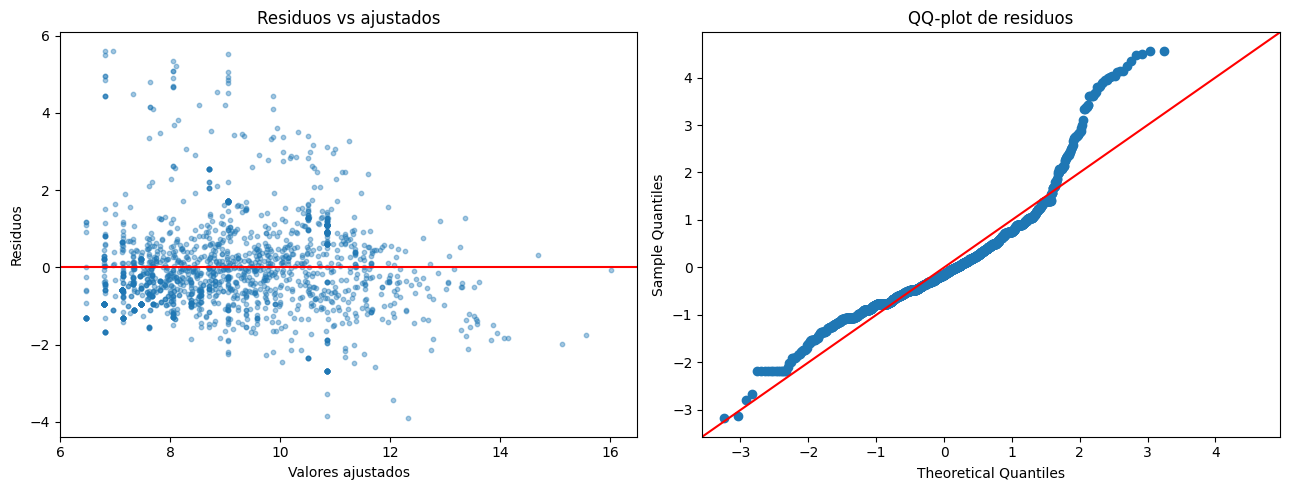

Sesgo de residuos: 1.34 | curtosis: 3.73
                                   r_simple  coef_simple  coef_multiple  beta_estandarizado  p_multiple
variable                                                                                               
n_marcas                             0.4625       0.8614         0.1824              0.0979      0.0000
log_n_folios                         0.4186       0.9922         0.2280              0.0962      0.0001
log_unidades                         0.3605       0.4807         0.4754              0.3565      0.0000
estado_principal_CIUDAD DE MEXICO   -0.2340      -1.0993        -0.3501             -0.0745      0.0000
marca_principal_AG                   0.2809       1.5097         2.2377              0.4164      0.0000
marca_principal_AIDITE               0.0570       0.2842         1.2243              0.2458      0.0000
marca_principal_ANAX DENT           -0.1105      -1.4993         0.5037              0.0371      0.0156
marca_principal_CREATIO

In [ ]:
# =====================================================================
# FASE 2: REGRESIÓN LINEAL SIMPLE Y MÚLTIPLE (puntos 4 y 5)
# Nivel de análisis: CLIENTE. Variable respuesta: log_total_comprado.
# =====================================================================

#1. Carga y preparación
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

if "cliente" not in globals():
    cliente = pd.read_pickle("df_cliente.pkl")

cl = cliente.copy()
cl["log_n_folios"] = np.log(cl["n_folios"])
cl["log_ticket"] = np.log(cl["ticket_prom_folio"])   # solo para mostrar la relación algebraica

Y = "log_total_comprado"
cand = ["n_marcas", "n_folios", "log_n_folios", "dias_activo", "log_unidades", "log_lineas"]

q1, q3 = cl[Y].quantile([.25, .75])
iqr = q3 - q1
mask_ok = (cl[Y] >= q1 - 1.5 * iqr) & (cl[Y] <= q3 + 1.5 * iqr)
print(f"Clientes: {len(cl)} | outliers IQR en {Y}: {(~mask_ok).sum()} | sesgo de {Y}: {cl[Y].skew():.2f}")

#2. Heatmaps de correlación (Pearson y Spearman)
vars_heat = [Y, "log_ticket"] + cand
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
for ax, met in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(cl[vars_heat].corr(method=met), annot=True, fmt=".2f",
                cmap="coolwarm", center=0, ax=ax)
    ax.set_title(f"Correlación de {met.capitalize()} (nivel cliente)")
plt.tight_layout()
plt.savefig("heatmap_correlaciones.png", dpi=150)
plt.show()

#3. Ranking de predictoras
rank = pd.DataFrame({
    "pearson": cl[cand].corrwith(cl[Y]),
    "spearman": cl[cand].corrwith(cl[Y], method="spearman"),
})
rank["abs_pearson"] = rank["pearson"].abs()
print(rank.sort_values("abs_pearson", ascending=False).round(3))
print("\nRelación algebraica (solo referencia): r(log_ticket, Y) =",
      round(cl["log_ticket"].corr(cl[Y]), 3))

#4. REGRESIÓN LINEAL SIMPLE
X_SIMPLE = rank["abs_pearson"].idxmax()   
print("Variable elegida para el modelo simple:", X_SIMPLE)

def ajustar_simple(d, x):
    return sm.OLS(d[Y], sm.add_constant(d[[x]])).fit()

m1 = ajustar_simple(cl, X_SIMPLE)
r = np.sign(m1.params[X_SIMPLE]) * np.sqrt(m1.rsquared)
print(f"\nEcuación: {Y} = {m1.params['const']:.4f} + {m1.params[X_SIMPLE]:.4f} * {X_SIMPLE}")
print(f"r = {r:.4f} | R2 = {m1.rsquared:.4f} | p-valor = {m1.pvalues[X_SIMPLE]:.3g} | n = {int(m1.nobs)}")

jit = 0.15 if cl[X_SIMPLE].nunique() < 20 else 0
plt.figure(figsize=(8, 6))
sns.regplot(data=cl, x=X_SIMPLE, y=Y, x_jitter=jit,
            scatter_kws={"alpha": .3, "s": 15}, line_kws={"color": "red"})
plt.title(f"{Y} vs {X_SIMPLE}  (r = {r:.3f}, R² = {m1.rsquared:.3f})")
plt.tight_layout()
plt.savefig("scatter_regresion_simple.png", dpi=150)
plt.show()

# Sensibilidad: sin outliers de la variable respuesta
m1s = ajustar_simple(cl[mask_ok], X_SIMPLE)
print(f"\nSensibilidad sin outliers (n = {int(m1s.nobs)}): "
      f"pendiente {m1s.params[X_SIMPLE]:.4f} | R2 {m1s.rsquared:.4f}  "
      f"(con todos: pendiente {m1.params[X_SIMPLE]:.4f} | R2 {m1.rsquared:.4f})")

#5. REGRESIÓN LINEAL MÚLTIPLE
num_x = ["n_marcas", "log_n_folios", "log_unidades"]        
cats = ["estado_principal", "marca_principal", "vendedor_principal"]

def dummies_ref(d, cats):
    partes = []
    for c in cats:
        ref = d[c].value_counts().idxmax()              
        dm = pd.get_dummies(d[c], prefix=c).drop(columns=f"{c}_{ref}")
        partes.append(dm)
        print(f"{c}: {d[c].nunique()} categorías | referencia = {ref}")
    return pd.concat(partes, axis=1)

X_full = pd.concat([cl[num_x], dummies_ref(cl, cats)], axis=1).astype(float)
print("Predictoras candidatas:", X_full.shape[1])

#6. Selección: primero VIF (> 5), luego eliminación hacia atrás por p-valor (> 0.05)
def vif_serie(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=X.columns)

X = X_full.copy()
while True:
    v = vif_serie(X)
    if v.max() <= 5:
        break
    print(f"Se quita por VIF = {v.max():.1f}: {v.idxmax()}")
    X = X.drop(columns=v.idxmax())

while True:
    m2 = sm.OLS(cl[Y], sm.add_constant(X)).fit()
    p = m2.pvalues.drop("const")
    if p.max() <= 0.05:
        break
    print(f"Se quita por p = {p.max():.3f}: {p.idxmax()}")
    X = X.drop(columns=p.idxmax())

print(m2.summary())
print(f"\nR2 = {m2.rsquared:.4f} | R2 ajustado = {m2.rsquared_adj:.4f} | n = {int(m2.nobs)} "
      f"| predictoras = {X.shape[1]} | VIF máx = {vif_serie(X).max():.2f}")

#7. Diagnóstico de residuos
res, fit = m2.resid, m2.fittedvalues
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(fit, res, s=10, alpha=.4)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("Valores ajustados")
ax[0].set_ylabel("Residuos")
ax[0].set_title("Residuos vs ajustados")
sm.qqplot(res, line="45", fit=True, ax=ax[1])
ax[1].set_title("QQ-plot de residuos")
plt.tight_layout()
plt.savefig("diagnostico_residuos.png", dpi=150)
plt.show()
print(f"Sesgo de residuos: {stats.skew(res):.2f} | curtosis: {stats.kurtosis(res):.2f}")

#8. Comparación: coeficientes del modelo simple vs el múltiple
sd_y = cl[Y].std()
filas = []
for v in X.columns:
    ms = sm.OLS(cl[Y], sm.add_constant(X[[v]])).fit()
    filas.append({
        "variable": v,
        "r_simple": X[v].corr(cl[Y]),
        "coef_simple": ms.params[v],
        "coef_multiple": m2.params[v],
        "beta_estandarizado": m2.params[v] * X[v].std() / sd_y,
        "p_multiple": m2.pvalues[v],
    })
comp = pd.DataFrame(filas).set_index("variable")
print(comp.round(4))

#9. Sensibilidad del modelo múltiple sin outliers de Y
idx = cl.index[mask_ok]
m2s = sm.OLS(cl.loc[idx, Y], sm.add_constant(X.loc[idx])).fit()
print(f"Con todos: R2 = {m2.rsquared:.4f} (n = {int(m2.nobs)}) | "
      f"sin outliers: R2 = {m2s.rsquared:.4f} (n = {int(m2s.nobs)})")
print(pd.DataFrame({"coef_todos": m2.params, "coef_sin_outliers": m2s.params}).round(4))

Partidas: 21,632 | sin costo (clase 1): 1,612 (7.45%)

=== A) con serie de folio (sin vendedor) | predictoras: 30 | dummies quitadas por separación: ['marca_g_ANAX DENT', 'marca_g_HUGE', 'marca_g_IPD', 'marca_g_JENSE']
Entrenamiento: 14,633 (7.39% sin costo) | Prueba: 6,999 (7.59% sin costo)
Exactitud de referencia (predecir siempre 'con costo'): 0.924


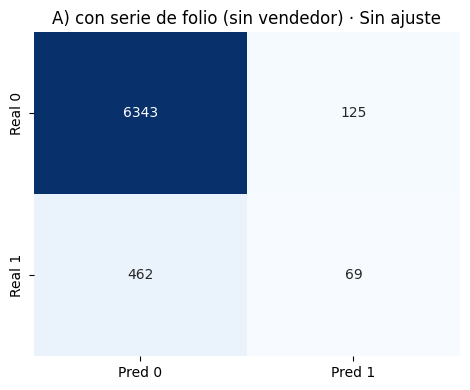

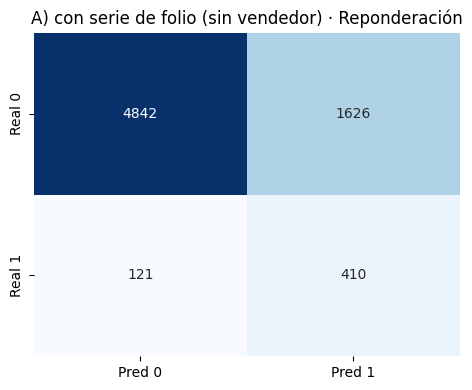

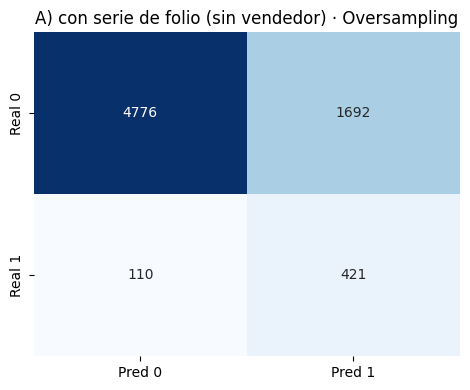

    escenario  VP   FP  FN   VN  exactitud  precision  sensibilidad  especificidad   AUC
   Sin ajuste  69  125 462 6343      0.916      0.356         0.130          0.981 0.829
Reponderación 410 1626 121 4842      0.750      0.201         0.772          0.749 0.842
 Oversampling 421 1692 110 4776      0.743      0.199         0.793          0.738 0.839

=== B) con vendedor (sin serie) | predictoras: 32 | dummies quitadas por separación: ['marca_g_ANAX DENT', 'marca_g_HUGE', 'marca_g_IPD', 'marca_g_JENSE']
Entrenamiento: 14,633 (7.39% sin costo) | Prueba: 6,999 (7.59% sin costo)
Exactitud de referencia (predecir siempre 'con costo'): 0.924


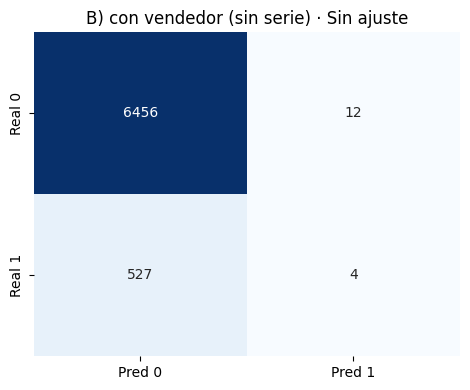

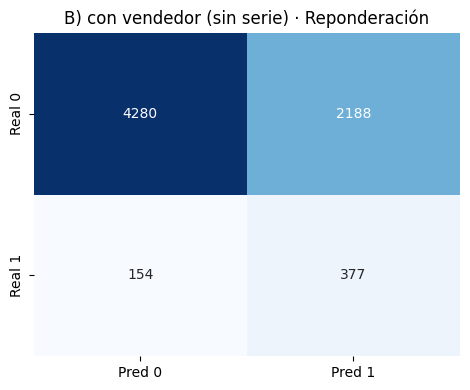

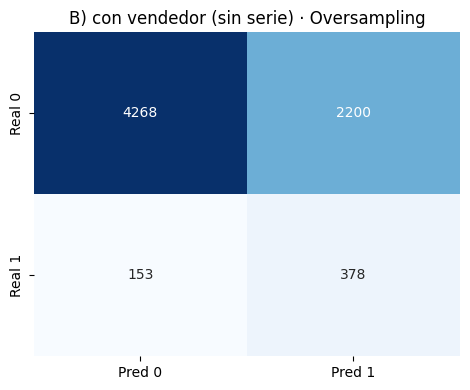

    escenario  VP   FP  FN   VN  exactitud  precision  sensibilidad  especificidad   AUC
   Sin ajuste   4   12 527 6456      0.923      0.250         0.008          0.998 0.758
Reponderación 377 2188 154 4280      0.665      0.147         0.710          0.662 0.768
 Oversampling 378 2200 153 4268      0.664      0.147         0.712          0.660 0.764

Comparación A vs B (conjunto de prueba):
   version     escenario  exactitud  precision  sensibilidad  especificidad   AUC
   A serie    Sin ajuste      0.916      0.356         0.130          0.981 0.829
   A serie Reponderación      0.750      0.201         0.772          0.749 0.842
   A serie  Oversampling      0.743      0.199         0.793          0.738 0.839
B vendedor    Sin ajuste      0.923      0.250         0.008          0.998 0.758
B vendedor Reponderación      0.665      0.147         0.710          0.662 0.768
B vendedor  Oversampling      0.664      0.147         0.712          0.660 0.764
                            

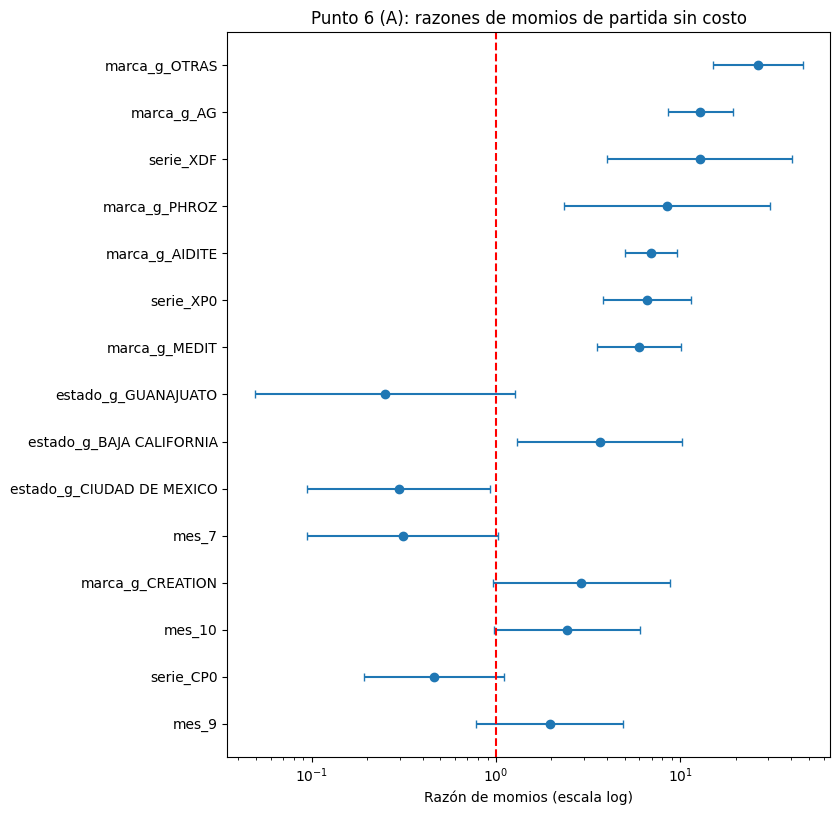

Corte de alto valor (percentil 75): total_comprado >= 47,413.79
Clientes: 1682 | alto valor: 426 (25.3%)

Clientes con valor 1 en cada variable:
multimarca          477
recurrente          785
volumen_alto        819
cdmx                425
marca_alto_valor    437
dtype: int64

% de clientes de alto valor según cada variable:
               n  pct_alto_valor
multimarca                      
0           1205           0.187
1            477           0.421 

              n  pct_alto_valor
recurrente                     
0           897           0.210
1           785           0.303 

                n  pct_alto_valor
volumen_alto                     
0             863           0.239
1             819           0.269 

         n  pct_alto_valor
cdmx                      
0     1257           0.286
1      425           0.158 

                     n  pct_alto_valor
marca_alto_valor                      
0                 1245           0.147
1                  437           0.556 

VI

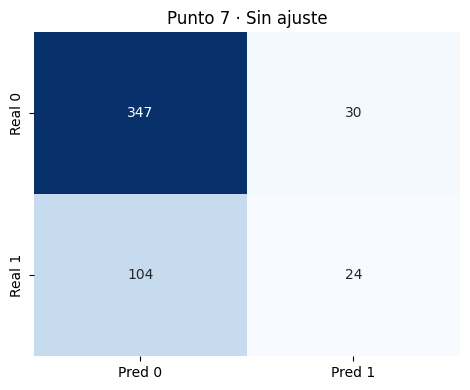

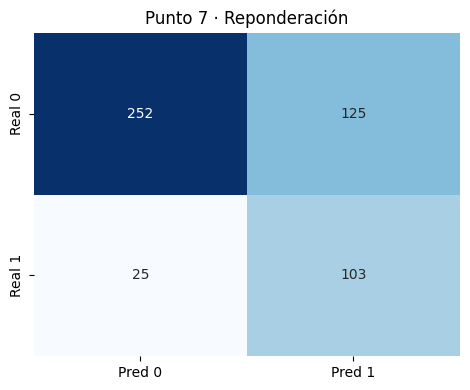

    escenario  VP  FP  FN  VN  exactitud  precision  sensibilidad  especificidad   AUC
   Sin ajuste  24  30 104 347      0.735      0.444         0.188          0.920 0.783
Reponderación 103 125  25 252      0.703      0.452         0.805          0.668 0.782
                   coef     OR  IC95_inf  IC95_sup  p_valor
multimarca        1.430  4.177     2.903     6.011    0.000
recurrente        0.253  1.288     0.862     1.924    0.216
volumen_alto     -0.140  0.870     0.597     1.267    0.467
cdmx             -0.461  0.630     0.456     0.871    0.005
marca_alto_valor  2.230  9.302     6.987    12.384    0.000

Pseudo-R2 de McFadden: 0.212 | n = 1682


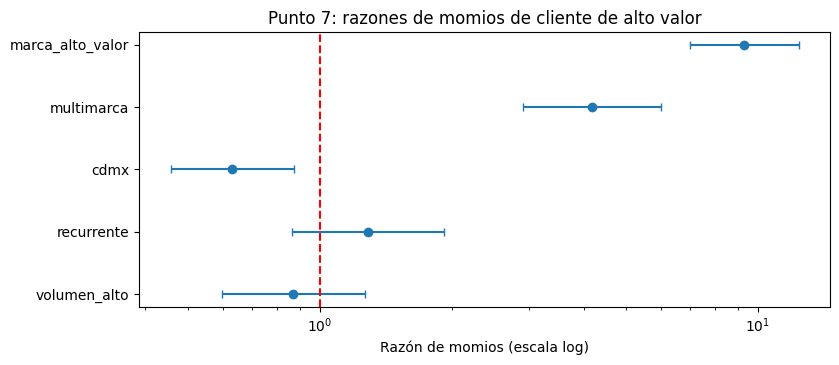

In [ ]:
# =====================================================================
# 04 · REGRESIÓN LOGÍSTICA (puntos 6 y 7)
# ---------------------------------------------------------------------
#
# PUNTO 6: respuesta dicotómica sin_costo (total_neto = 0),
#   con tres escenarios: sin ajuste, reponderación de clases y oversampling.
#   Se corren DOS versiones del modelo:
#     A) con serie de folio, sin vendedor  -> modelo principal del reporte
#     B) con vendedor, sin serie de folio  -> comparación
#   No pueden combinarse: las dummies de vendedor y de serie (XDF, CDF, B00)
#   son linealmente dependientes (colinealidad exacta), así que se compara
#   cuál aporta más información (AUC de A = 0.84 vs B = 0.77).
#
# PUNTO 7: variables convertidas a dicotómicas; respuesta
#   alto_valor = total comprado >= percentil 75.
# =====================================================================

# Parámetros 
SEMILLA = 42                      # semilla para reproducir particiones y oversampling
PERCENTIL = 0.75                  # corte de "alto valor"
MARCAS_ALTO = ["MEDIT", "AG"]    

# %% 0b. Librerías, carga y funciones auxiliares
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.utils import resample
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)

if "df" not in globals():
    df = pd.read_pickle("df_partidas_limpio.pkl")
if "cliente" not in globals():
    cliente = pd.read_pickle("df_cliente.pkl")

def ajustar(X, y, class_weight=None):
    return LogisticRegression(C=1e6, max_iter=5000, class_weight=class_weight).fit(X, y)


def sobremuestrear(X, y, semilla=SEMILLA):
    """Oversampling aleatorio de la clase minoritaria (solo sobre entrenamiento)."""
    pos, neg = X[y == 1], X[y == 0]
    pos_up = resample(pos, replace=True, n_samples=len(neg), random_state=semilla)
    Xb = pd.concat([neg, pos_up])
    yb = pd.Series([0] * len(neg) + [1] * len(pos_up), index=Xb.index)
    return Xb, yb


def evaluar(nombre, modelo, Xte, yte, titulo=None, archivo=None):
    pred = modelo.predict(Xte)
    prob = modelo.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    fila = {
        "escenario": nombre, "VP": tp, "FP": fp, "FN": fn, "VN": tn,
        "exactitud": (tp + tn) / (tp + tn + fp + fn),
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "sensibilidad": tp / (tp + fn) if (tp + fn) else 0.0,
        "especificidad": tn / (tn + fp) if (tn + fp) else 0.0,
        "AUC": roc_auc_score(yte, prob),
    }
    if archivo:
        plt.figure(figsize=(4.8, 4))
        sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=["Pred 0", "Pred 1"], yticklabels=["Real 0", "Real 1"])
        plt.title(titulo or nombre)
        plt.tight_layout()
        plt.savefig(archivo, dpi=150)
        plt.show()
    return fila


def forest(tabla, titulo, archivo, n_max=15):
    """Gráfica de razones de momios con IC 95% (escala log)."""
    t = tabla.dropna(subset=["IC95_inf", "IC95_sup"]).copy()
    t["magnitud"] = np.abs(np.log(t["OR"]))
    t = t.sort_values("magnitud", ascending=False).head(n_max).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(t) + 1.5))
    ax.errorbar(t["OR"], range(len(t)),
                xerr=[t["OR"] - t["IC95_inf"], t["IC95_sup"] - t["OR"]],
                fmt="o", capsize=3)
    ax.axvline(1, color="red", ls="--")
    ax.set_xscale("log")
    ax.set_yticks(range(len(t)))
    ax.set_yticklabels(t.index)
    ax.set_xlabel("Razón de momios (escala log)")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.savefig(archivo, dpi=150)
    plt.show()


# =====================================================================
# PUNTO 6 — NIVEL PARTIDA: ¿qué partidas salen sin costo?
# =====================================================================

# %% 1. Preparación
d = df.copy()
d["y"] = d["sin_costo"].astype(int)
d["serie"] = d["folio_g"].replace({"TL0": "OTRA_SERIE"})
d["mes"] = d["fecha_documento"].dt.month.astype(str)
d["log_unidades"] = np.log(d["total_unidades"])

print(f"Partidas: {len(d):,} | sin costo (clase 1): {d['y'].sum():,} ({d['y'].mean()*100:.2f}%)")
# FUGA DE INFORMACIÓN: precio_unitario y total_neto NO entran (revelan la respuesta).


def armar_X(d, cats):
    partes = [d[["log_unidades"]]]
    for c in cats:
        ref = d[c].value_counts().idxmax()             
        partes.append(pd.get_dummies(d[c], prefix=c).drop(columns=f"{c}_{ref}"))
    X = pd.concat(partes, axis=1).astype(float)
    # Se quitan dummies con separación perfecta (todo 0 o todo 1 en la respuesta)
    quitadas = [c for c in X.columns if c != "log_unidades"
                and (d.loc[X[c] == 1, "y"].sum() == 0 or d.loc[X[c] == 1, "y"].mean() == 1)]
    return X.drop(columns=quitadas), quitadas


# %% 2. Función que ajusta los 3 escenarios (sin ajuste, reponderación, oversampling)
def correr(cats, etiqueta):
    X, quitadas = armar_X(d, cats)
    y = d["y"]
    # Partición por FOLIO (las partidas de un mismo folio no se separan entre entrenamiento
    # y prueba) y ESTRATIFICADA (misma proporción de partidas sin costo en ambos): 2/3 y 1/3.
    sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
    tr, te = next(sgkf.split(X, y, groups=d["folio"]))
    Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    # Revisión de colinealidad exacta entre dummies (rango de la matriz de diseño)
    rango = np.linalg.matrix_rank(sm.add_constant(X).values)
    if rango < X.shape[1] + 1:
        print(f"ADVERTENCIA: colinealidad exacta (rango {rango} de {X.shape[1] + 1} columnas)")
    print(f"\n=== {etiqueta} | predictoras: {X.shape[1]} | dummies quitadas por separación: {quitadas}")
    print(f"Entrenamiento: {len(Xtr):,} ({ytr.mean()*100:.2f}% sin costo) | "
          f"Prueba: {len(Xte):,} ({yte.mean()*100:.2f}% sin costo)")

    print(f"Exactitud de referencia (predecir siempre 'con costo'): {1 - yte.mean():.3f}")
    Xo, yo = sobremuestrear(Xtr, ytr)
    modelos = {"Sin ajuste": ajustar(Xtr, ytr),
               "Reponderación": ajustar(Xtr, ytr, "balanced"),
               "Oversampling": ajustar(Xo, yo)}
    tags = {"Sin ajuste": "sin_ajuste", "Reponderación": "reponderacion", "Oversampling": "oversampling"}
    filas = [evaluar(k, m, Xte, yte, titulo=f"{etiqueta} · {k}",
                     archivo=f"matriz_confusion_p6_{etiqueta[0]}_{tags[k]}.png")
             for k, m in modelos.items()]
    met = pd.DataFrame(filas)
    print(met.round(3).to_string(index=False))
    return {"Xtr": Xtr, "ytr": ytr, "Xte": Xte, "yte": yte, "modelos": modelos, "metricas": met}


# %% 3. Versión A (con serie de folio) y versión B (con vendedor)
# Serie y vendedor NO van juntos (colinealidad exacta): se comparan dos versiones.
resA = correr(["serie", "marca_g", "estado_g", "mes"], "A) con serie de folio (sin vendedor)")
resB = correr(["vendedor_g", "marca_g", "estado_g", "mes"], "B) con vendedor (sin serie)")

comp = pd.concat([resA["metricas"].assign(version="A serie"),
                  resB["metricas"].assign(version="B vendedor")])
print("\nComparación A vs B (conjunto de prueba):")
print(comp[["version", "escenario", "exactitud", "precision", "sensibilidad",
            "especificidad", "AUC"]].round(3).to_string(index=False))


# %% 4. Razones de momios (versión A) con errores estándar agrupados por folio
def tabla_or(res):
    Xtr, ytr = res["Xtr"], res["ytr"]
    grupos = pd.factorize(d.loc[Xtr.index, "folio"])[0]
    Xc = sm.add_constant(Xtr)
    try:
        lg = sm.Logit(ytr, Xc).fit(disp=0, maxiter=200, cov_type="cluster",
                                   cov_kwds={"groups": grupos})
    except Exception:
        lg = sm.Logit(ytr, Xc).fit(disp=0, method="bfgs", maxiter=2000, cov_type="cluster",
                                   cov_kwds={"groups": grupos})
    ci = lg.conf_int()
    t = pd.DataFrame({"OR": np.exp(lg.params), "IC95_inf": np.exp(ci[0]),
                      "IC95_sup": np.exp(ci[1]), "p_valor": lg.pvalues}).drop("const")
    for k, nombre in [("Reponderación", "OR_reponderado"), ("Oversampling", "OR_oversampling")]:
        t[nombre] = np.exp(pd.Series(res["modelos"][k].coef_[0], index=Xtr.columns))
    return t


orA = tabla_or(resA)
print(orA.sort_values("OR", ascending=False).round(3).to_string())
forest(orA, "Punto 6 (A): razones de momios de partida sin costo", "forest_punto6.png")
# OR > 1: aumenta la probabilidad de que la partida sea sin costo frente a la categoría de referencia.


# =====================================================================
# PUNTO 7 — NIVEL CLIENTE: variables convertidas a dicotómicas
# =====================================================================

# %% 5. Construcción de las variables dicotómicas
c = cliente.copy()
base = df[df["sin_costo"] == 0]
# Marca principal por NÚMERO DE PARTIDAS (no por gasto) para no mezclarla con la respuesta
c["marca_principal_lineas"] = base.groupby("nombre_cliente")["marca_g"].agg(
    lambda x: x.value_counts().idxmax())

corte = c["total_comprado"].quantile(PERCENTIL)
c["alto_valor"] = (c["total_comprado"] >= corte).astype(int)                    

c["multimarca"] = (c["n_marcas"] >= 2).astype(int)
c["recurrente"] = (c["n_folios"] >= 2).astype(int)
c["volumen_alto"] = (c["unidades"] > c["unidades"].median()).astype(int)
c["cdmx"] = (c["estado_principal"] == "CIUDAD DE MEXICO").astype(int)
c["marca_alto_valor"] = c["marca_principal_lineas"].isin(MARCAS_ALTO).astype(int)

preds = ["multimarca", "recurrente", "volumen_alto", "cdmx", "marca_alto_valor"]
print(f"Corte de alto valor (percentil {PERCENTIL*100:.0f}): total_comprado >= {corte:,.2f}")
print(f"Clientes: {len(c)} | alto valor: {c['alto_valor'].sum()} ({c['alto_valor'].mean()*100:.1f}%)")
print("\nClientes con valor 1 en cada variable:")
print(c[preds].sum())
print("\n% de clientes de alto valor según cada variable:")
for v in preds:
    print(c.groupby(v)["alto_valor"].agg(n="size", pct_alto_valor="mean").round(3), "\n")

# %% 6. Colinealidad entre las dicotómicas
Xc7 = sm.add_constant(c[preds].astype(float))
vif = pd.Series([variance_inflation_factor(Xc7.values, i) for i in range(1, Xc7.shape[1])],
                index=preds)
print("VIF:\n", vif.round(2))

# %% 7. Clasificación: sin ajuste vs reponderación de clases (partición estratificada 70/30)
X7, y7 = c[preds].astype(float), c["alto_valor"]
Xtr7, Xte7, ytr7, yte7 = train_test_split(X7, y7, test_size=0.30, stratify=y7, random_state=SEMILLA)
print(f"Entrenamiento: {len(Xtr7)} ({ytr7.mean()*100:.1f}% alto valor) | "
      f"Prueba: {len(Xte7)} ({yte7.mean()*100:.1f}% alto valor)")

mod7 = {"Sin ajuste": ajustar(Xtr7, ytr7), "Reponderación": ajustar(Xtr7, ytr7, "balanced")}
tags7 = {"Sin ajuste": "sin_ajuste", "Reponderación": "reponderacion"}
met7 = pd.DataFrame([evaluar(k, m, Xte7, yte7, titulo=f"Punto 7 · {k}",
                             archivo=f"matriz_confusion_p7_{tags7[k]}.png")
                     for k, m in mod7.items()])
print(met7.round(3).to_string(index=False))

# %% 8. Razones de momios (modelo explicativo con todos los clientes) e interpretación
lg7 = sm.Logit(y7, sm.add_constant(X7)).fit(disp=0)
ci7 = lg7.conf_int()
or7 = pd.DataFrame({"coef": lg7.params, "OR": np.exp(lg7.params),
                    "IC95_inf": np.exp(ci7[0]), "IC95_sup": np.exp(ci7[1]),
                    "p_valor": lg7.pvalues}).drop("const")
print(or7.round(3).to_string())
print(f"\nPseudo-R2 de McFadden: {lg7.prsquared:.3f} | n = {int(lg7.nobs)}")
forest(or7, "Punto 7: razones de momios de cliente de alto valor", "forest_punto7.png", n_max=10)
# Nota
# El modelo es EXPLICATIVO. Variables como n_folios o unidades forman parte del comportamiento que construye el total;
# se reporta como asociación, no como causa.